In [3]:
import pandas as pd
df = pd.read_csv("data/retail_sales_dataset.csv")
print("Dataset:", df.shape)

display(df.head())

print("\nColumns names:")
print(df.columns.tolist())

print("\n data types and missing values")
df.info()


print("\n missing values per columns")
print(df.isnull().sum())

Dataset: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100



Columns names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

 data types and missing values
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

 missing values per columns
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quan

In [4]:
#Data quality checks

df_clean = df.copy()

df_clean["Date"] = pd.to_datetime(df_clean["Date"], errors="coerce")

print("duplicates rows:", df_clean.duplicated().sum())

print("duplicate transations IDs", df_clean["Transaction ID"].duplicated().sum())

print("\nmissing values:")
print(df_clean.isnull().sum())

print("\n numerical summaries:")
print(df_clean.describe())

print("\n product categories:")
print(df_clean["Product Category"].value_counts())

print("\nInvalid dates:", df_clean["Date"].isnull().sum())
print("Age <= 0:", (df_clean["Age"] <= 0).sum())
print("Quantity <= 0:", (df_clean["Quantity"] <= 0).sum())
print("Price per Unit <= 0:", (df_clean["Price per Unit"] <= 0).sum())
print("Total Amount <= 0:", (df_clean["Total Amount"] <= 0).sum())


expected_amount = (
    df_clean["Quantity"] * df_clean["Price per Unit"]
)
print(
    "\nAmount calcultion mismatch:",
    (df_clean["Total Amount"] != expected_amount).sum()
)

print("\nDate data type:", df_clean["Date"].dtype)



duplicates rows: 0
duplicate transations IDs 0

missing values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

 numerical summaries:
       Transaction ID                           Date         Age     Quantity  \
count     1000.000000                           1000  1000.00000  1000.000000   
mean       500.500000  2023-07-03 00:25:55.200000256    41.39200     2.514000   
min          1.000000            2023-01-01 00:00:00    18.00000     1.000000   
25%        250.750000            2023-04-08 00:00:00    29.00000     1.000000   
50%        500.500000            2023-06-29 12:00:00    42.00000     3.000000   
75%        750.250000            2023-10-04 00:00:00    53.00000     4.000000   
max       1000.000000            2024-01-01 00:00:00    64.00000     4.000000   
std        288.819436                            NaN  

In [5]:

print("Date range:")
print("Start:", df_clean["Date"].min())
print("End:", df_clean["Date"].max())

print("\nAmount calculation check:")
expected_amount = (
    df_clean["Quantity"] * df_clean["Price per Unit"]
)

mismatches = df_clean[
    df_clean["Total Amount"] != expected_amount
]

print("Mismatched transactions:", len(mismatches))

print("\nFull numerical summary:")
display(
    df_clean[
        ["Age", "Quantity", "Price per Unit", "Total Amount"]
    ].describe().round(2)
)

print("\nData types after conversion:")
print(df_clean.dtypes)


Date range:
Start: 2023-01-01 00:00:00
End: 2024-01-01 00:00:00

Amount calculation check:
Mismatched transactions: 0

Full numerical summary:


,Age,Quantity,Price per Unit,Total Amount
count,1000.00,1000.00,1000.00,1000.0
mean,41.39,2.51,179.89,456.0
std,13.68,1.13,189.68,560.0
min,18.00,1.00,25.00,25.0
25%,29.00,1.00,30.00,60.0
50%,42.00,3.00,50.00,135.0
75%,53.00,4.00,300.00,900.0
max,64.00,4.00,500.00,2000.0



Data types after conversion:
Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object


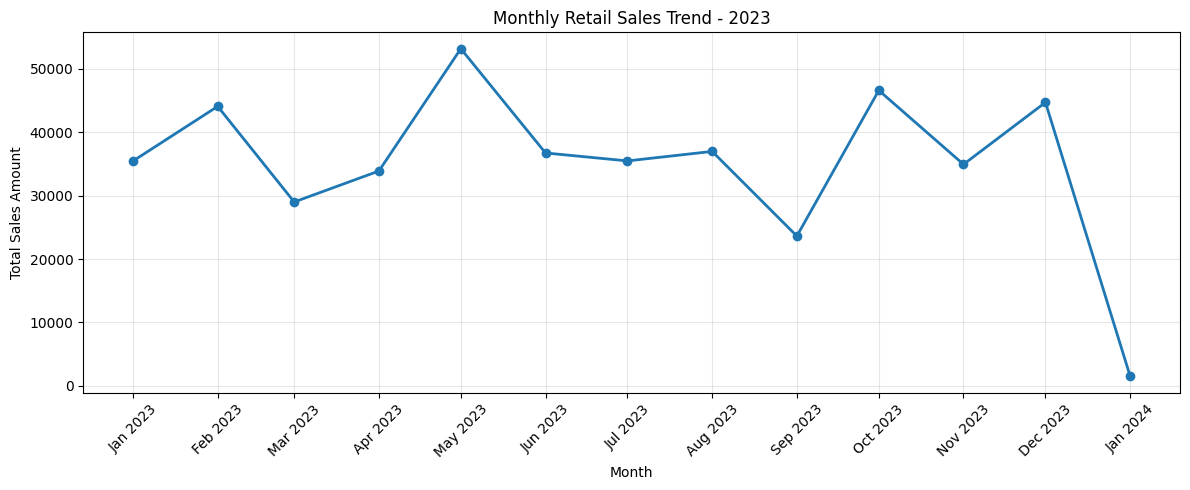

,Total Sales
Date,
2023-01-01,35450
2023-02-01,44060
2023-03-01,28990
2023-04-01,33870
2023-05-01,53150
2023-06-01,36715
2023-07-01,35465
2023-08-01,36960
2023-09-01,23620


In [6]:

import matplotlib.pyplot as plt
import pandas as pd

# Group sales by month
monthly_sales = (
    df_clean
    .set_index("Date")["Total Amount"]
    .resample("MS")
    .sum()
)

# Plot monthly sales
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Retail Sales Trend - 2023")
plt.xlabel("Month")
plt.ylabel("Total Sales Amount")
plt.xticks(monthly_sales.index, monthly_sales.index.strftime("%b %Y"), rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly_sales.rename("Total Sales").to_frame())


### Monthly Sales Trend — Observations

- May 2023 recorded the highest monthly sales of 53,150.
- September 2023 recorded the lowest full-month sales of 23,620.
- Sales fluctuated throughout the year rather than following a consistent upward or downward trend.
- Sales recovered in October to 46,580 after declining in September.
- January 2024 shows sales of only 1,530. Since the dataset contains a transaction dated January 1, 2024, this month may be incomplete and should not be compared directly with full months.

**Business insight:** The business should investigate the reasons behind the sales decline in September and examine the factors associated with stronger sales in May and October. The available data shows the pattern but does not establish its cause.

Customer transactions by gender:


,Transactions
Gender,
Female,510
Male,490


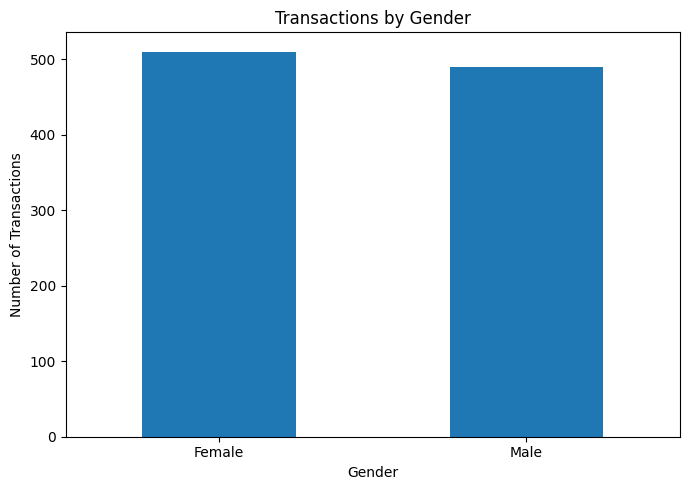

In [8]:

Gender_counts = df_clean["Gender"].value_counts()

print("Customer transactions by gender:")
display(gender_counts.to_frame(name="Transactions"))

plt.figure(figsize=(7, 5))
gender_counts.plot(kind="bar")

plt.title("Transactions by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Gender Analysis — Observations

- Female customers account for 510 transactions (51%).
- Male customers account for 490 transactions (49%).
- The difference between the two groups is 20 transactions, indicating a nearly balanced transaction distribution.
- Transaction counts alone do not show which gender generates more revenue or has a higher average purchase value.

**Business insight:** The retailer should avoid focusing exclusively on one gender based on transaction count. Comparing revenue and average transaction value by gender could help identify meaningful differences in purchasing behaviour.

Transactions by age group:


,Transactions
Age Group,
18-25,169
26-35,205
36-45,202
46-55,229
56-64,195


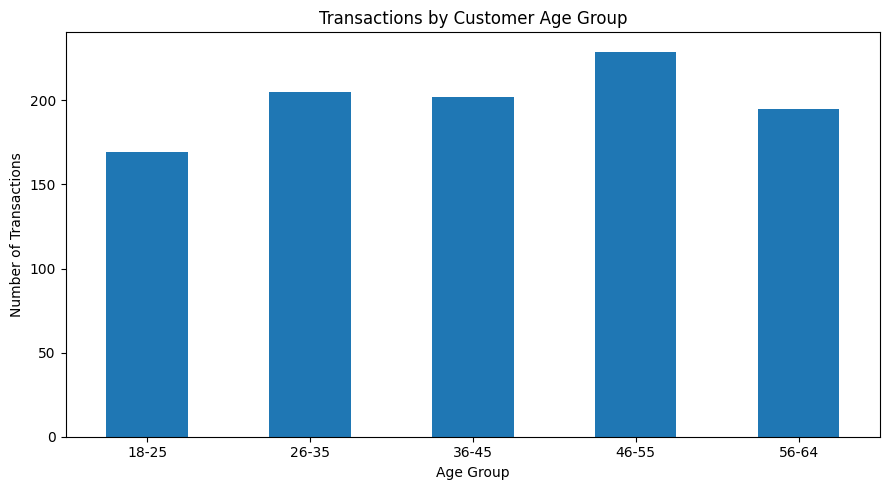

In [9]:

# Customer age groups

age_bins = [17, 25, 35, 45, 55, 65]
age_labels = ["18-25", "26-35", "36-45", "46-55", "56-64"]

df_clean["Age Group"] = pd.cut(
    df_clean["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

age_counts = (
    df_clean["Age Group"]
    .value_counts()
    .sort_index()
)

print("Transactions by age group:")
display(age_counts.to_frame(name="Transactions"))

plt.figure(figsize=(9, 5))
age_counts.plot(kind="bar")

plt.title("Transactions by Customer Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Customer Age-Group Analysis — Observations

- Customers aged 46–55 account for the highest number of transactions, with 229 transactions (22.9%).
- Customers aged 18–25 account for the lowest number, with 169 transactions (16.9%).
- The remaining age groups contribute between 19.5% and 20.5% of transactions.
- Transaction activity is spread across all five age groups rather than being concentrated in only one group.

**Business insight:** The retailer could compare product-category preferences and average transaction value across age groups before designing targeted promotions. Transaction counts alone do not establish which group generates the most revenue.

Revenue by product category:


,Total Revenue
Product Category,
Electronics,156905
Clothing,155580
Beauty,143515



Quantity sold by product category:


,Total Quantity
Product Category,
Clothing,894
Electronics,849
Beauty,771


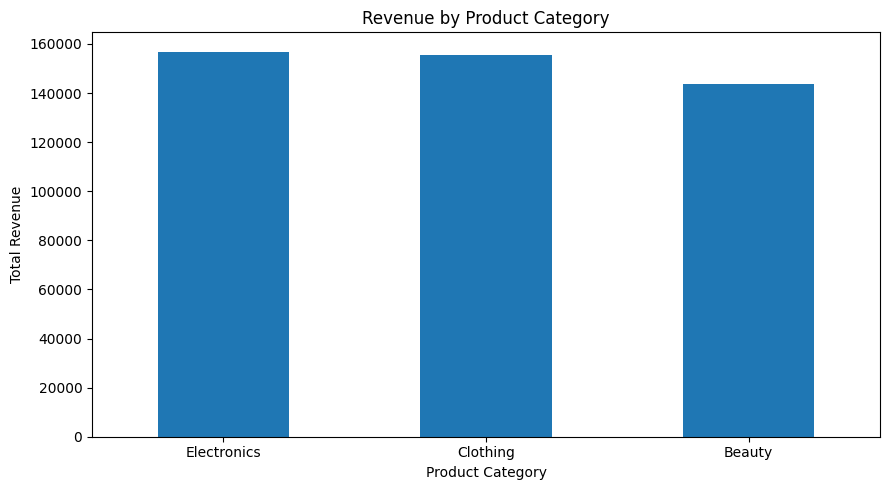

In [10]:

category_sales = (
    df_clean.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

category_quantity = (
    df_clean.groupby("Product Category")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

print("Revenue by product category:")
display(category_sales.to_frame(name="Total Revenue"))

print("\nQuantity sold by product category:")
display(category_quantity.to_frame(name="Total Quantity"))

plt.figure(figsize=(9, 5))
category_sales.plot(kind="bar")

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Product Category Analysis — Observations

- Electronics generated the highest total revenue of 156,905.
- Clothing generated revenue of 155,580 and recorded the highest quantity sold at 894 units.
- Beauty generated the lowest revenue of 143,515, with 771 units sold.
- Electronics generated only 1,325 more revenue than Clothing, indicating similar total revenue performance between these two categories.
- Clothing sold more units than Electronics but generated slightly less revenue.

**Business insight:** The retailer should investigate the average selling price and purchasing patterns of each category. Clothing may offer opportunities to increase revenue per unit, while Electronics' strong revenue performance could justify reviewing stock availability. These are recommendations to investigate, not proven causes.

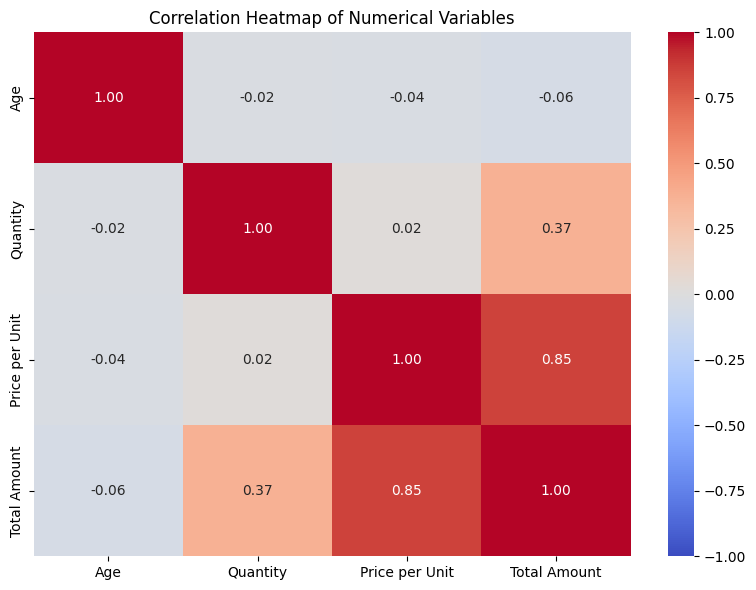

In [11]:

import seaborn as sns
import matplotlib.pyplot as plt

numeric_cols = [
    "Age",
    "Quantity",
    "Price per Unit",
    "Total Amount"
]

correlation_matrix = df_clean[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()


### Correlation Heatmap — Observations

- Price per Unit and Total Amount have a strong positive correlation of 0.85.
- Quantity and Total Amount have a moderate positive correlation of 0.37.
- Age has very weak linear correlations with Quantity (-0.02), Price per Unit (-0.04), and Total Amount (-0.06).
- Quantity and Price per Unit have an almost zero correlation of 0.02.

**Business insight:** Transaction value is more closely associated with price per unit than with customer age in this dataset. The retailer could examine transaction quantities, pricing, and product-category performance together to understand sales patterns. These correlations do not establish causation, and Total Amount is calculated from Quantity and Price per Unit.

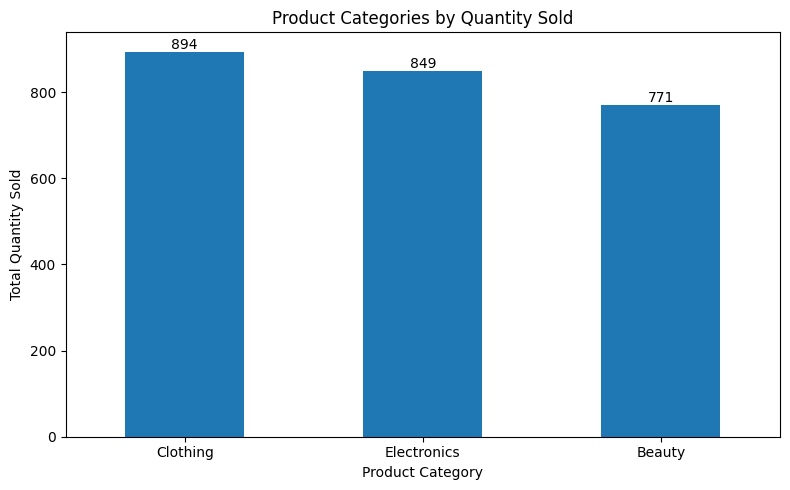

In [12]:

top_categories = (
    df_clean.groupby("Product Category")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
ax = top_categories.plot(kind="bar")

plt.title("Product Categories by Quantity Sold")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=0)

for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height())}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


### Product Quantity Analysis — Observations

- Clothing recorded the highest quantity sold, with 894 units.
- Electronics ranked second with 849 units, while Beauty recorded the lowest quantity at 771 units.
- Clothing sold 123 more units than Beauty.
- The category with the highest sales quantity is not necessarily the category with the highest revenue. Electronics generated the highest revenue despite selling fewer units than Clothing.

**Business insight:** The retailer should review category-level pricing and sales volume together when making inventory and promotional decisions. Clothing's higher sales volume may justify monitoring stock availability, while Beauty's lower volume could be investigated further before changing its marketing strategy.

Revenue and transaction summary by gender:


,sum,mean,count
Gender,,,
Female,232840,456.55,510
Male,223160,455.43,490


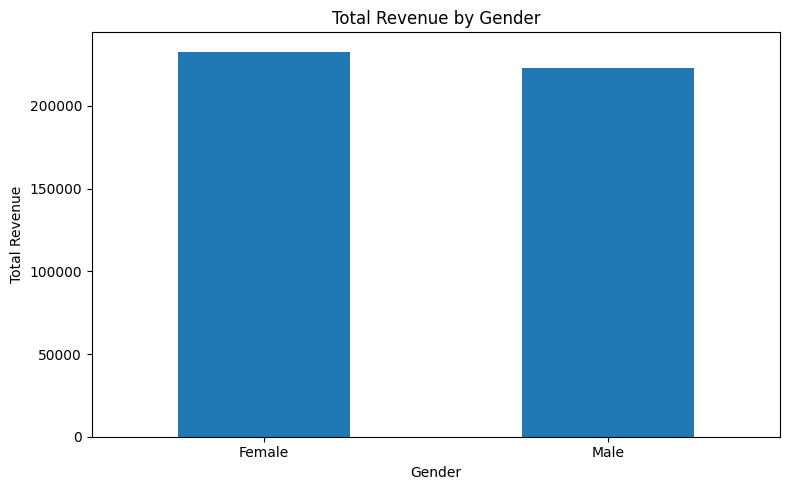

In [13]:

gender_revenue = (
    df_clean.groupby("Gender")["Total Amount"]
    .agg(["sum", "mean", "count"])
    .round(2)
)

print("Revenue and transaction summary by gender:")
display(gender_revenue)

plt.figure(figsize=(8, 5))
gender_revenue["sum"].plot(kind="bar")

plt.title("Total Revenue by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Additional Analysis — Revenue by Gender

- Female transactions generated total revenue of 232,840 across 510 transactions.
- Male transactions generated total revenue of 223,160 across 490 transactions.
- Female revenue was 9,680 higher than male revenue.
- The average transaction values were very similar: 456.55 for females and 455.43 for males.

**Business insight:** Although female transactions generated slightly higher total revenue, the average transaction value was almost identical across the two groups. The difference in total revenue is therefore consistent with the slightly higher number of female transactions. Further analysis by age group and product category may reveal more actionable patterns.

Quarterly Sales:


,Total Sales
Date,
2023-01-01,108500
2023-04-01,123735
2023-07-01,96045
2023-10-01,126190
2024-01-01,1530


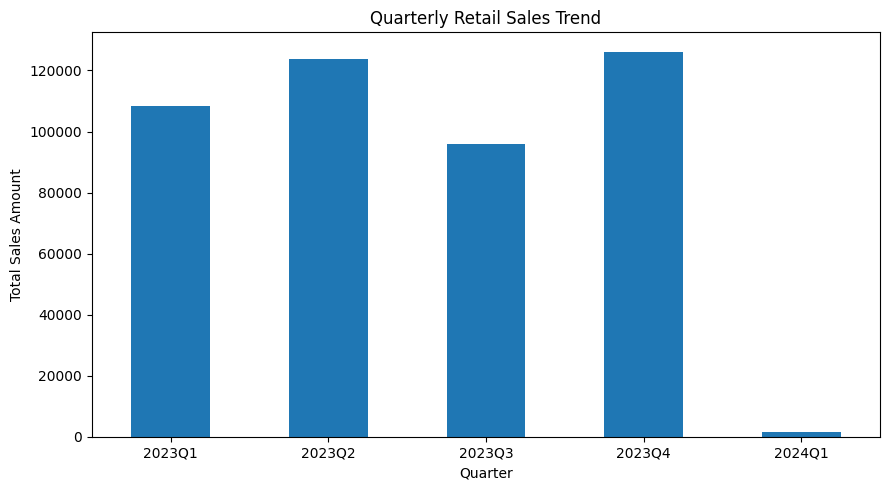

In [14]:

quarterly_sales = (
    df_clean
    .set_index("Date")["Total Amount"]
    .resample("QS")
    .sum()
)

print("Quarterly Sales:")
display(quarterly_sales.to_frame(name="Total Sales"))

plt.figure(figsize=(9, 5))
quarterly_sales.plot(kind="bar")

plt.title("Quarterly Retail Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales Amount")
plt.xticks(
    range(len(quarterly_sales)),
    quarterly_sales.index.to_period("Q").astype(str),
    rotation=0
)
plt.tight_layout()
plt.show()


### Quarterly Sales Trend — Observations

- Q2 2023 sales increased to 123,735 from 108,500 in Q1 2023.
- Q3 2023 recorded the lowest full-quarter sales at 96,045.
- Q4 2023 recovered to 126,190, the highest quarterly sales total of 2023.
- The quarterly trend shows fluctuations rather than consistent growth.
- Q1 2024 recorded only 1,530 in sales and represents a partial quarter in this dataset.

**Business insight:** The retailer should investigate the decline in Q3 and examine what contributed to the stronger performance in Q4. The observed pattern alone does not establish the cause, so promotions, product mix, and transaction patterns should be reviewed before making business changes.

## Conclusion and Business Recommendations

This exploratory data analysis examined 1,000 retail transactions across three product categories: Electronics, Clothing, and Beauty. The dataset contained no reported missing values or duplicate rows, and all transaction amounts matched the quantity multiplied by price per unit.

The analysis found that Electronics generated the highest revenue at 156,905, while Clothing recorded the highest quantity sold at 894 units. May 2023 was the strongest month by sales, and Q4 2023 was the strongest quarter. Gender-wise revenue and average transaction values were similar. The correlation analysis showed a strong positive relationship between price per unit and total transaction amount.

### Business Recommendations

1. **Review seasonal sales patterns:** Investigate the September sales decline and the strong May and Q4 performance to identify opportunities for better campaign planning.
2. **Monitor category-level inventory:** Review Clothing's high unit volume and Electronics' high revenue when planning inventory and promotions.
3. **Improve category performance:** Investigate Beauty's lower revenue and quantity sold before deciding whether targeted promotions or product-mix changes are appropriate.
4. **Use customer segmentation carefully:** Compare spending and category preferences across age groups instead of relying on transaction counts alone.
5. **Track complete reporting periods:** Exclude or separately label incomplete periods, such as Q1 2024, when comparing monthly or quarterly sales.

### Limitations

The dataset contains transaction-level information but no individual product names, costs, profit margins, or marketing data. Therefore, individual top-selling products, profitability, and the causes of sales fluctuations cannot be established from this dataset alone.